# Dogs vs. Cats Image Classification with Keras CNN
#### Practice image classification notebook using a Convolutional Neural Network (CNN) with BatchNormalization and Dropout in TensorFlow/Keras to classify images as cats or dogs.   

In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Conv2D, Flatten, MaxPool2D, BatchNormalization, Dropout
from google.colab import userdata

## 1. Kaggle Authentication & Dataset Download
#### Configure Kaggle credentials from Colab user secrets and download the salader/dogsvscats dataset into /content/dogs_vs_cats

In [2]:
os.environ["Kaggle_api"] = userdata.get("Kaggle_api")

In [3]:
!kaggle datasets download \
    -d salader/dogsvscats \
    -p /content/dogs_vs_cats \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/salader/dogsvscats
License(s): unknown
100% 1.06G/1.06G [00:16<00:00, 68.9MB/s]



## 2. Load Image Datasets & Normalize Pixel Values
#### Load the training and test image directories at (256, 256) resolution with a batch size of 32, and normalize pixel values to [0.0, 1.0] as tf.float32.

In [4]:
train_ds = keras.utils.image_dataset_from_directory(
    directory="/content/dogs_vs_cats/train",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256)
)

test_ds = keras.utils.image_dataset_from_directory(
    directory="/content/dogs_vs_cats/test",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256)
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [5]:
def process(image, label):
    image = tf.cast(image / 255.0, tf.float32)
    return image, label


train_ds = train_ds.map(process)
test_ds = test_ds.map(process)

## 3. CNN Model Architecture & Compilation
#### Build a Sequential CNN with three Conv2D + BatchNormalization + MaxPool2D blocks (32, 64, and 128 filters), flatten the feature maps, add two Dense layers (128 and 64 units with Dropout(0.1)), and finish with a sigmoid output unit (Dense(1, activation="sigmoid")).

In [6]:
model = Sequential([
    Conv2D(32, kernel_size=(3, 3), padding="valid", activation="relu", input_shape=(256, 256, 3)),
    BatchNormalization(),
    MaxPool2D(pool_size=(2, 2), strides=2, padding="valid"),
    Conv2D(64, kernel_size=(3, 3), padding="valid", activation="relu"),
    BatchNormalization(),
    MaxPool2D(pool_size=(2, 2), strides=2, padding="valid"),
    Conv2D(128, kernel_size=(3, 3), padding="valid", activation="relu"),
    BatchNormalization(),
    MaxPool2D(pool_size=(2, 2), strides=2, padding="valid"),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.1),
    Dense(64, activation="relu"),
    Dropout(0.1),
    Dense(1, activation="sigmoid")
])

model.summary()

model.compile(optimizer="Adam", loss="binary_crossentropy", metrics=["accuracy"])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

## 4. Train Model & Plot Accuracy Curves
#### Train the CNN for 10 epochs (625 batches per epoch) using test_ds as validation data, then plot training versus validation accuracy across epochs.

In [7]:
history = model.fit(train_ds, epochs=10, validation_data=test_ds)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 87s 107ms/step - accuracy: 0.5969 - loss: 1.4168 - val_accuracy: 0.6524 - val_loss: 0.6306
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 62s 99ms/step - accuracy: 0.6980 - loss: 0.5750 - val_accuracy: 0.7220 - val_loss: 0.5724
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 62s 100ms/step - accuracy: 0.7451 - loss: 0.5243 - val_accuracy: 0.7748 - val_loss: 0.4850
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 64s 103ms/step - accuracy: 0.7987 - loss: 0.4344 - val_accuracy: 0.6826 - val_loss: 0.6859
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 62s 99ms/step - accuracy: 0.8390 - loss: 0.3663 - val_accuracy: 0.5992 - val_loss: 1.1110
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 64s 103ms/step - accuracy: 0.8743 - loss: 0.2937 - val_accuracy: 0.7986 - val_loss: 0.5212
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 62s 99ms/step - accuracy: 0.9129 - loss: 0.2142 - val_accuracy: 0.8136 - val_loss: 0.5142
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 98ms/step - accuracy: 0.9453 - loss: 0.134

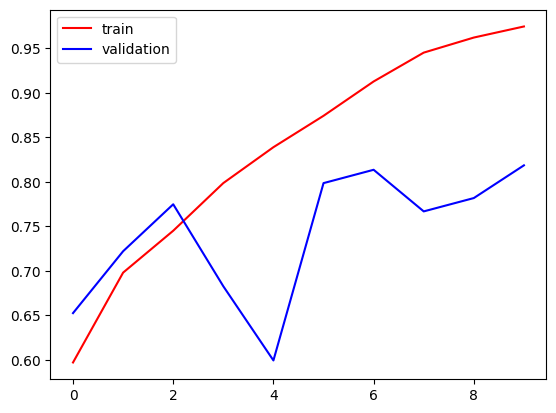

In [8]:
plt.plot(history.history["accuracy"], color="red", label="train")
plt.plot(history.history["val_accuracy"], color="blue", label="validation")
plt.legend()
plt.show()

## 5. Single-Image Inference
#### Load /content/cat_2.jpg, inspect its original shape, resize to (256, 256), normalize pixel values, reshape into a batch of 1, and run model.predict.

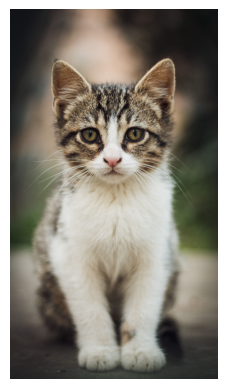

In [10]:
test_img = plt.imread("/content/cat_2.jpg")
plt.imshow(test_img)
plt.axis("off")
plt.show()

In [11]:
test_img.shape

(5472, 3078, 3)

In [12]:
test_img_resized = cv2.resize(test_img, (256, 256)) / 255.0
test_input = test_img_resized.reshape((1, 256, 256, 3))

In [13]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


array([[0.00063148]], dtype=float32)